# Module 3 — The social cost of carbon: putting damages and discounting together

**Project:** *Pricing the Future*, an empirical extension of my M.Sc. project (University of Bath).

The **social cost of carbon (SCC)** is the present value of all the future damage caused by emitting one more tonne of CO₂ today. Governments use it to value the benefits of climate policy: Canada's official figure is C\$247 per tonne for 2020 emissions (ECCC 2023), which adopts the US EPA's \$190 (2020 US\$, 2% discount rate).

$$\text{SCC} = \sum_{t=1}^{H} DF(t)\; D(t)$$

- $D(t)$ comes from **Module 1**: how much one tonne's extra warming lowers world GDP in year $t$.
- $DF(t)$ comes from **Module 2**: the eight discount schedules estimated from data.

This notebook computes the SCC under every combination, puts a **confidence interval** on each one, and asks which assumptions actually drive the answer. All computation lives in `python/climate_discount/scc.py` (unit-tested in `python/tests/test_scc.py`).

In [1]:
# --- Setup -------------------------------------------------------------------
import sys, os
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir("..")
sys.path.insert(0, str(Path.cwd() / "python"))

import numpy as np
import pandas as pd
from IPython.display import Image, display
pd.options.display.float_format = "{:,.1f}".format

import run_scc
out = run_scc.main()
res, summary, countries, coefs = out["results"], out["summary"], out["countries"], out["coefs"]


================ STEP 4 KEY RESULTS ================
Base year 2025; 182 countries; world GDP $98T (2015 US$); GDP-weighted temperature 12.7°C
Benchmark: EPA/ECCC $190 (2020 US$) ≈ $174 in 2015 US$

persistence                            Level effect (λ=0)           Growth effect (λ=1)          
damage_spec                                        Pooled Rich/poor              Pooled Rich/poor
method                                                                                           
Constant 2.0% (US mean real rate)                    13.1       1.0             1,136.3      51.7
Gamma (Weitzman survey)                              16.8       1.9             2,226.1     185.5
Gamma (US real-rate history)                         67.3       9.8            11,393.4   1,115.4
Newell-Pizer AR(1), US                               14.7       1.2             1,365.6      70.9
Newell-Pizer random walk, US                         81.1      12.2            14,618.4   1,487.7
Ramsey SDF, Ster

## 1. The chain of the calculation

| Step | Assumption | Source |
|---|---|---|
| **Climate** | One tonne raises temperature permanently by 0.45 °C per 1,000 GtCO₂ (likely range 0.27–0.63) | IPCC AR6 (TCRE) |
| **Baseline warming** | +1.3 °C more by 2100, flat afterwards, applied to every country | Roughly the IPCC's middle-of-the-road scenario |
| **Baseline growth** | GDP per capita growth easing from 2% to 1% by 2100; population growth fading to 0 by 2080 | Stylised |
| **Damage function** | $\partial\,\text{growth}/\partial T = \beta_1 + 2\beta_2 T$ for each country, at its own temperature | **Module 1** (pooled, or rich/poor) |
| **Persistence** | Growth effect (λ = 1): a lost year of growth is never recovered. Level effect (λ = 0): output bounces back | Both reported |
| **Discounting** | Eight schedules: constant, gamma ×2, Newell–Pizer ×2, Ramsey SDF ×3 | **Module 2** |
| **Horizon** | Damages to 2300 | As in EPA (2023) |

**An exact confidence interval.** The damage stream is *linear* in the two regression coefficients, so $\text{SCC} = \beta_1 a + \beta_2 b$ for numbers $a, b$ that depend only on the scenario and the discount schedule. The SCC's standard error then follows exactly from the regression's covariance matrix, with no simulation:

$$\text{Var}(\text{SCC}) = \begin{bmatrix} a & b \end{bmatrix} V_\beta \begin{bmatrix} a \\ b \end{bmatrix}$$

In [2]:
print(f"Base year: {summary['base_year']} | countries: {summary['n_countries']} | "
      f"world GDP: ${summary['world_gdp_base_2015usd_trillion']:.0f} trillion (2015 US$)")
print(f"GDP-weighted average temperature: {summary['gdp_weighted_temp']:.1f}°C")
print(f"Pooled growth-maximising temperature T* = {coefs['main']['t_opt']:.1f}°C")

# Where does world GDP sit relative to T*? Damages depend on it.
share_above = countries.gdp[countries.temp > coefs["main"]["t_opt"]].sum() / countries.gdp.sum()
print(f"Share of world GDP in countries hotter than T*: {share_above:.0%}")

Base year: 2025 | countries: 182 | world GDP: $98 trillion (2015 US$)
GDP-weighted average temperature: 12.7°C
Pooled growth-maximising temperature T* = 8.1°C
Share of world GDP in countries hotter than T*: 74%


## 2. Results

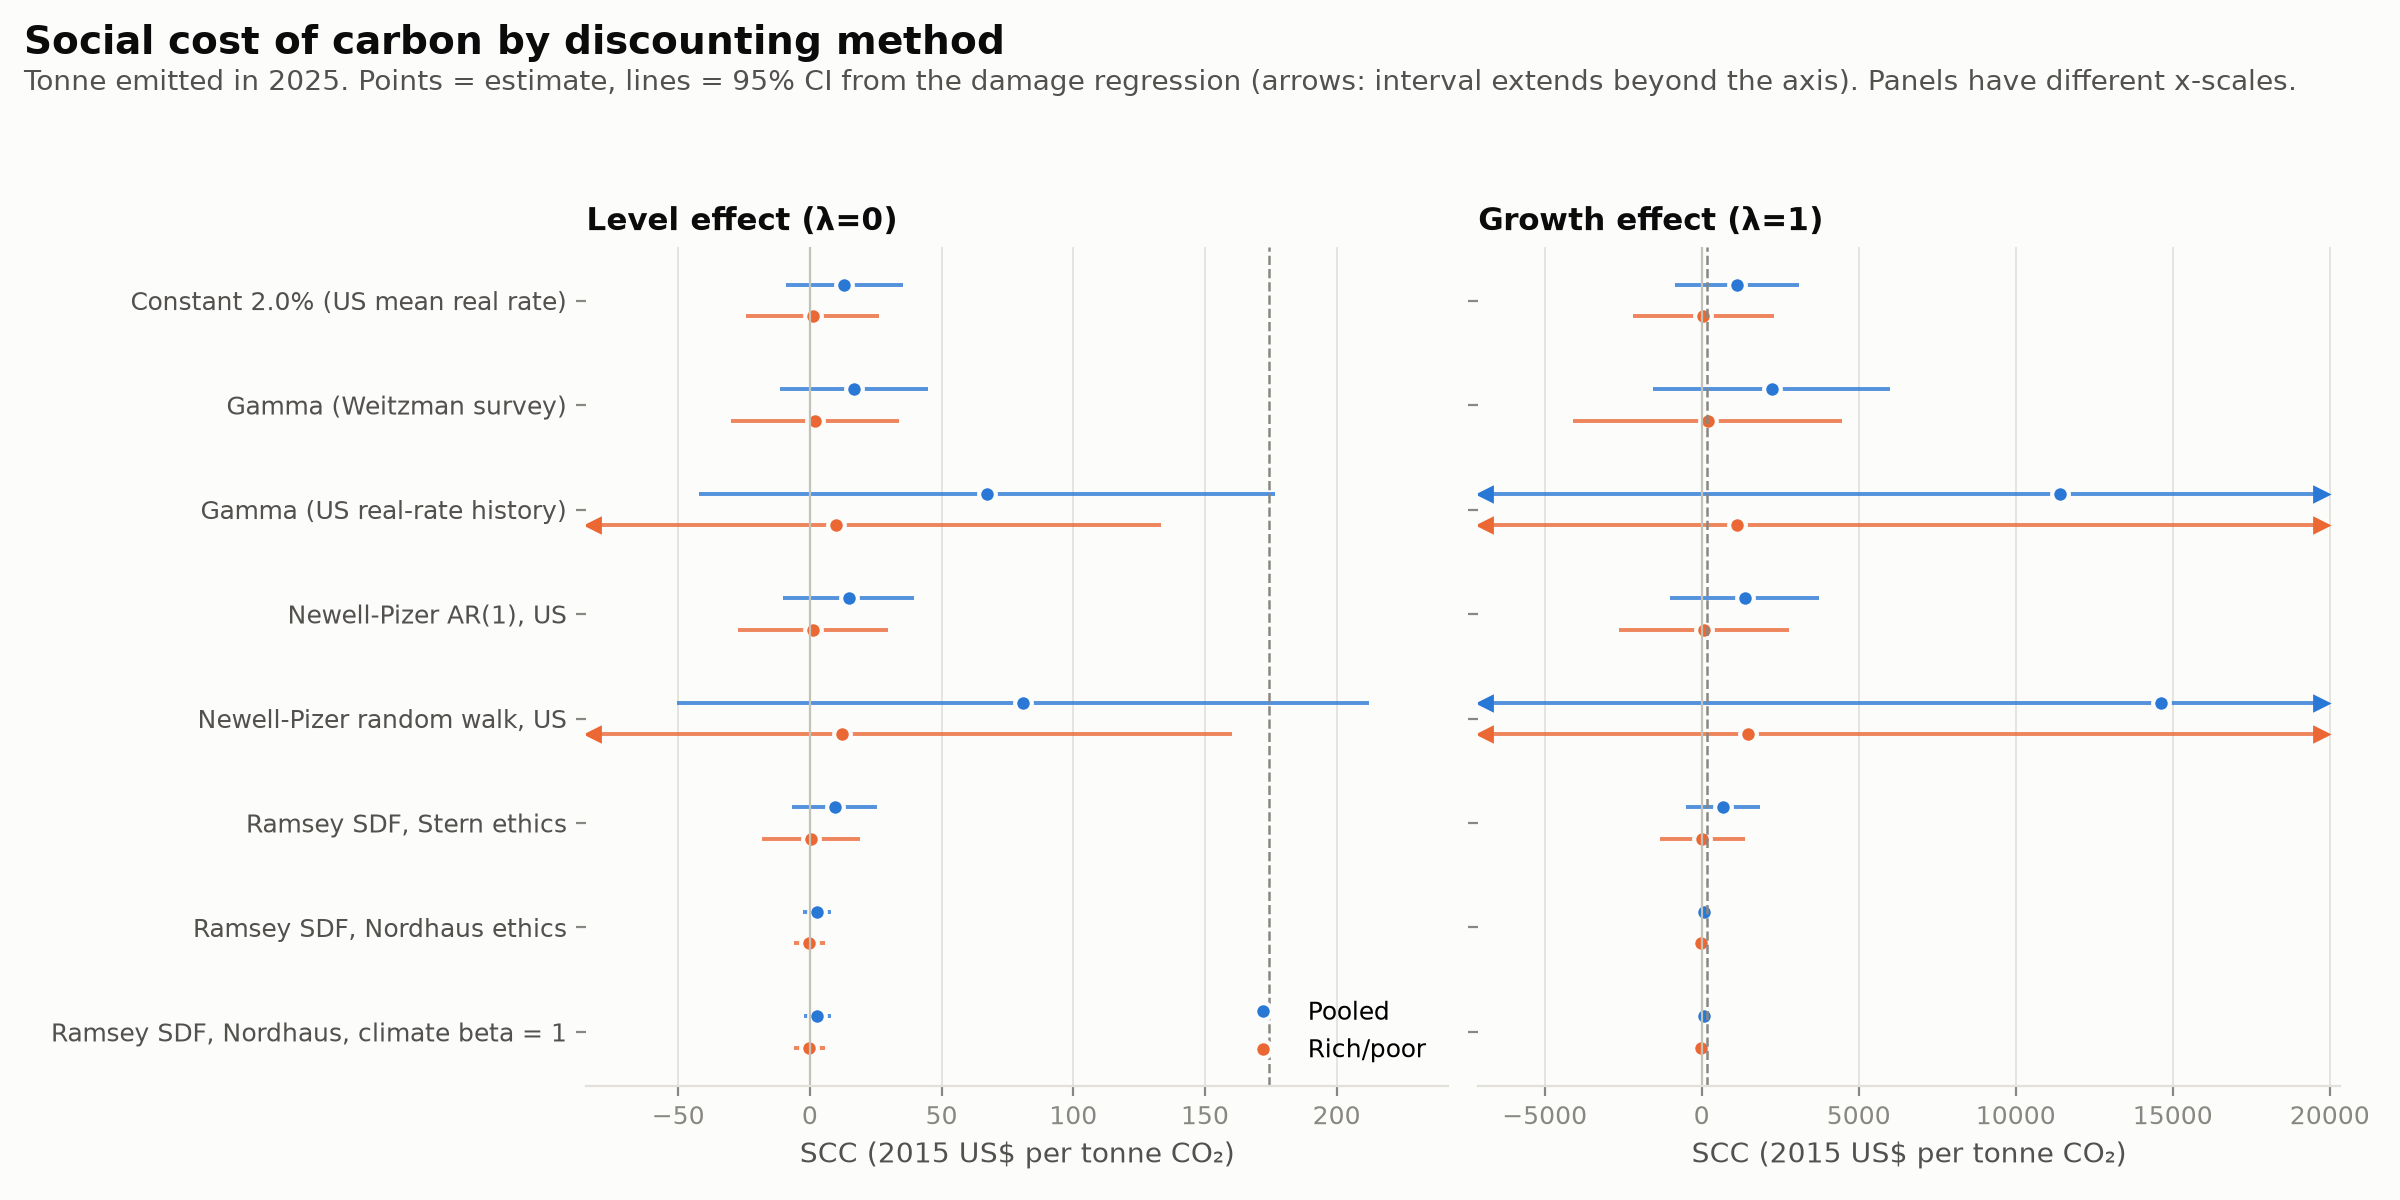

In [3]:
display(Image("output/figures/fig6_scc_by_method.png", width=1000))

In [4]:
# Full table: SCC (2015 US$ per tonne) with 95% confidence intervals
tbl = res.assign(**{"95% CI": res.apply(lambda r: f"[{r.ci_low:,.0f}, {r.ci_high:,.0f}]", axis=1)})
tbl[["persistence", "damage_spec", "method", "scc", "95% CI", "pv_to_2100", "pv_after_2100"]] \
    .rename(columns={"scc": "SCC", "pv_to_2100": "PV to 2100", "pv_after_2100": "PV after 2100"}) \
    .style.format({"SCC": "{:,.0f}", "PV to 2100": "{:,.0f}", "PV after 2100": "{:,.0f}"}).hide(axis="index")

persistence,damage_spec,method,SCC,95% CI,PV to 2100,PV after 2100
Level effect (λ=0),Pooled,Constant 2.0% (US mean real rate),13,"[-9, 35]",6,7
Level effect (λ=0),Pooled,Gamma (Weitzman survey),17,"[-11, 45]",5,12
Level effect (λ=0),Pooled,Gamma (US real-rate history),67,"[-42, 177]",9,59
Level effect (λ=0),Pooled,"Newell-Pizer AR(1), US",15,"[-10, 40]",7,8
Level effect (λ=0),Pooled,"Newell-Pizer random walk, US",81,"[-50, 212]",8,73
Level effect (λ=0),Pooled,"Ramsey SDF, Stern ethics",9,"[-7, 26]",5,4
Level effect (λ=0),Pooled,"Ramsey SDF, Nordhaus ethics",3,"[-2, 8]",3,0
Level effect (λ=0),Pooled,"Ramsey SDF, Nordhaus, climate beta = 1",3,"[-2, 8]",3,0
Level effect (λ=0),Rich/poor,Constant 2.0% (US mean real rate),1,"[-24, 26]",-0,1
Level effect (λ=0),Rich/poor,Gamma (Weitzman survey),2,"[-30, 34]",-0,2


### Benchmark: the official SCC

EPA's \$190 (2020 US\$) is about \$174 in our 2015 US\$ units (dashed line in the chart). Which of our estimates land near it?

In [5]:
bench = summary["epa_in_2015usd_approx"]["2.0%"]
near = res.assign(ratio=res.scc / bench).sort_values("ratio")
near[["persistence", "damage_spec", "method", "scc", "ratio"]] \
    .rename(columns={"ratio": "× EPA"}) \
    .style.format({"scc": "{:,.0f}", "× EPA": "{:.2f}"}).hide(axis="index")

persistence,damage_spec,method,scc,× EPA
Growth effect (λ=1),Rich/poor,"Ramsey SDF, Nordhaus ethics",-6,-0.04
Growth effect (λ=1),Rich/poor,"Ramsey SDF, Nordhaus, climate beta = 1",-6,-0.04
Level effect (λ=0),Rich/poor,"Ramsey SDF, Nordhaus, climate beta = 1",-0,-0.00
Level effect (λ=0),Rich/poor,"Ramsey SDF, Nordhaus ethics",-0,-0.00
Level effect (λ=0),Rich/poor,"Ramsey SDF, Stern ethics",0,0.00
Level effect (λ=0),Rich/poor,Constant 2.0% (US mean real rate),1,0.01
Level effect (λ=0),Rich/poor,"Newell-Pizer AR(1), US",1,0.01
Level effect (λ=0),Rich/poor,Gamma (Weitzman survey),2,0.01
Level effect (λ=0),Pooled,"Ramsey SDF, Nordhaus, climate beta = 1",3,0.02
Level effect (λ=0),Pooled,"Ramsey SDF, Nordhaus ethics",3,0.02


## 3. When do the damages occur?

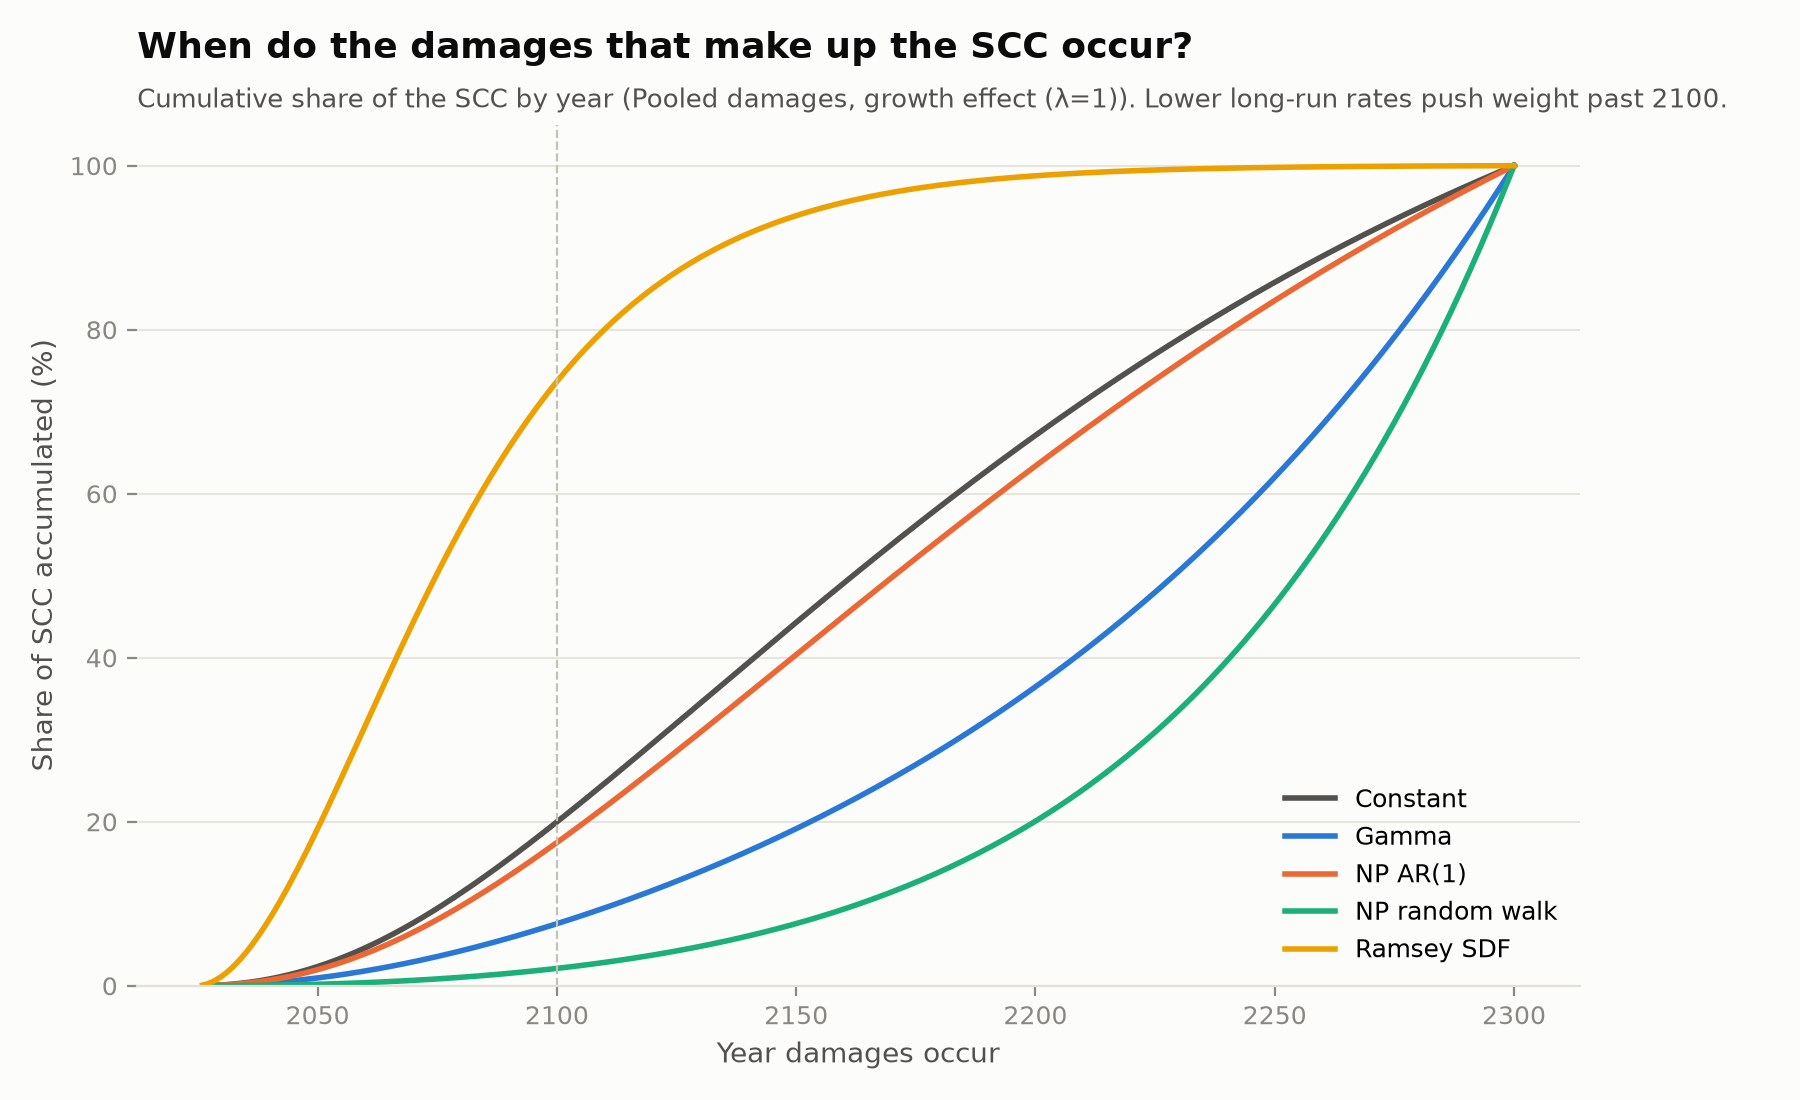

In [6]:
display(Image("output/figures/fig7_scc_by_horizon.png", width=850))

With growth effects, losses compound: a tonne emitted today keeps lowering GDP growth every year, so damages keep rising for centuries. How much of that counts depends on the discount rate: the higher the long-run rate, the more of the SCC comes from damages before 2100. Under declining rates, most of it comes later, which also means **the 2300 cut-off itself matters**: with growth effects and low long-run rates, the SCC keeps rising the further out you count. (The chart uses pooled damages; with rich/poor damages the stream starts negative, because cold rich countries gain at first, so a cumulative share is not meaningful.)

## 4. Which assumption matters most?

In [7]:
# Decompose the spread: hold everything else fixed, vary one dimension at a time.
central = dict(persistence="Growth effect (λ=1)", damage_spec="Rich/poor", method_key="Constant")
def pick(**kw):
    q = res
    for k, v in {**central, **kw}.items():
        q = q[q[k] == v]
    return float(q.scc.iloc[0])

c0 = pick()
rows = [
    ("Discounting method (8 schedules)",
     min(res[(res.persistence == central["persistence"]) & (res.damage_spec == central["damage_spec"])].scc),
     max(res[(res.persistence == central["persistence"]) & (res.damage_spec == central["damage_spec"])].scc)),
    ("Persistence (level vs growth)", pick(persistence="Level effect (λ=0)"), c0),
    ("Damage spec (pooled vs rich/poor)", *sorted([c0, pick(damage_spec="Pooled")])),
    ("Warming per tonne (IPCC likely range)",
     c0 * summary["tcre_scaling_low_high"][0], c0 * summary["tcre_scaling_low_high"][1]),
    ("Damage-regression uncertainty (95% CI)",
     *res[(res.persistence == central["persistence"]) & (res.damage_spec == central["damage_spec"]) &
          (res.method_key == "Constant")][["ci_low", "ci_high"]].iloc[0].tolist()),
]
spread = pd.DataFrame(rows, columns=["varying", "low", "high"])
spread["range ($)"] = spread.high - spread.low
print(f"Central case: rich/poor damages, growth effect, constant-rate discounting -> SCC ${c0:,.0f}\n")
spread.sort_values("range ($)", ascending=False).style.format(
    {"low": "{:,.0f}", "high": "{:,.0f}", "range ($)": "{:,.0f}"}).hide(axis="index")

Central case: rich/poor damages, growth effect, constant-rate discounting -> SCC $52



varying,low,high,range ($)
Damage-regression uncertainty (95% CI),"-2,202","2,306","4,508"
Discounting method (8 schedules),-6,"1,488","1,494"
Damage spec (pooled vs rich/poor),52,"1,136","1,085"
Persistence (level vs growth),1,52,51
Warming per tonne (IPCC likely range),31,72,41


## 5. Takeaways

**1. The official SCC sits inside our range, but the range is enormous.** Across 32 combinations of discounting method, damage specification and persistence, the SCC for a tonne emitted in 2025 runs from slightly negative to **\$14,618** (2015 US\$). The EPA/ECCC benchmark (\$190 in 2020 US\$ ≈ \$174 in 2015 US\$) is matched most closely by rich/poor damages with growth effects and gamma (Weitzman) discounting (\$186).

**2. Persistence is the first-order question.** At a constant 2% rate with pooled damages, the SCC is **\$13** if temperature shocks cause one-off losses (level effect) and **\$1,136** if lost growth is never recovered (growth effect), an 87-fold difference. The regression identifies the effect on *growth* but not how long it lasts. The official figure effectively takes a middle position on this unresolved question.

**3. Discounting is the second.** With pooled growth effects, the SCC ranges **180-fold** across methods: \$82 (Nordhaus Ramsey SDF), \$1,136 (constant 2%), \$2,226 (Weitzman gamma) and \$14,618 (Newell–Pizer random walk). The methods that assume the most uncertainty about future rates give the highest values, because they put most weight on damages after 2100 (over 95% of the total for the random walk). This confirms the original paper's central claim, now with parameters estimated from data, and shows that the 2300 cut-off itself shapes the answer.

**4. Damage-function uncertainty is as large as either.** The SCC is linear in the two regression coefficients, so its confidence interval is exact. Every 95% interval in Figure 6 includes zero: with 60 years of weather shocks, the curvature of the damage function is estimated, but not precisely enough to pin down the sign of the global SCC.

**5. Whose damages count changes the answer: an equity-weighting result.** Letting rich and poor countries have their own damage functions lowers the SCC about 20-fold (\$1,136 → \$52 at 2%). Rich countries hold most of world GDP and have a flat damage curve with an optimum near 10°C, so many gain slightly in the coming decades (the present value of damages to 2100 is *negative*, about −\$20). Poor countries are hurt far more, but their losses are small *in dollars*. A dollar-denominated SCC weights \$1 lost in Nigeria the same as \$1 lost in the US. Equity weighting, which values losses by poorer people more highly, would raise this estimate substantially.

**6. Physics adds ±40%.** The IPCC's likely range for warming per tonne scales every estimate by ×0.6 to ×1.4.

**Limitations.** One warming path for all countries (no regional patterns), no adaptation, damages only through GDP growth (no mortality, sea-level rise or tipping points), a common GDP growth path, and area-weighted temperatures (see Module 1).

**Hand-off to Module 4.** The Ramsey SDF implies an almost negligible risk premium for climate damages (a climate beta of 1 changes the SCC by under 5%). Module 4 asks whether **financial markets** price temperature risk more heavily, using 49 US industry portfolios.